## 0. The Dataset

This project uses **PAWS-Wiki (Paraphrase Adversaries from Word Scrambling)**, a dataset designed for binary paraphrase detection and introduced by Zhang et al. (2019). Each instance consists of two sentences labelled according to whether they convey the same meaning.

PAWS-Wiki contains sentence pairs with high lexical overlap but potentially different meanings. This makes it particularly challenging for models that rely primarily on word occurrence and frequency.

The dataset was selected to investigate the limitations of lexical representations and assess whether incorporating word-order information improves paraphrase detection.


## 1. Tokenizer and word embedding for PAWS

For this section we should choose a tokenizer and a type of embedding.

As constructing an embedding from a word is a non-trivial task in NLP, we will use pretrained embeddings. These pretrained embeddings, like GloVe, fastText and Word2Vec, have vocabularies and tokens that are generally quite generic, so they can be used for different classification tasks. Therefore, the tokenizer must be compatible with this approach, i.e. we should be able to match the pretrained embeddings with the tokens in our corpus.

For this reason, we will discard using subword tokenizers (BPE, WordPiece, SentencePiece...), character tokenizers or hybrid approaches. We will also avoid tokenizing our texts simply by splitting on spaces, as this is too simplistic. We want to preserve the meaning of our sentence pairs to be able to distinguish them, and splitting only on spaces would not properly separate punctuation, which can sometimes change their meaning.

Therefore, the tokenizer we will use is `BasicTokenizer`, keeping punctuation and stopwords. To generalize a bit, we will only change capital letters to lowercase, as this will rarely change the meaning of a sentence, although some distinctions may be lost. With PAWS, aggressive changes to sentences, such as removing stopwords, could lead to losing part of the signal, understanding signal as information relevant to meaning. E.g. "from Paris to Madrid" and "from Madrid to Paris": removing stopwords would leave the same words, "Paris" and "Madrid", but in different orders. These phrases would then be indistinguishable to a bag-of-words or mean-pooling representation, which ignores word order.


In [1]:
# Load packages
import sys
import matplotlib.pyplot as plt
from pathlib import Path
sys.path.append(str(Path("..").resolve()))
from src.part2_utils import BasicTokenizer, CleanTokenizer, PretrainedEmbeddings, build_embedding_matrix, build_vocab
from src.part2_utils import cos_similarity, topk_ids, analyse_embs
from sklearn.metrics import roc_auc_score
from src.dataset import load_paws
import pandas as pd
import numpy as np
import torch

In [2]:
# Load and split the PAWS dataset
dataset = load_paws()
train_ds = dataset["train"]
validation_ds = dataset["validation"]
test_ds = dataset["test"]
split_info = pd.DataFrame([
    {
        "Split": split_name,
        "Instances": len(split_data),
        "Columns": ", ".join(split_data.column_names)
    }
    for split_name, split_data in dataset.items()
])

display(split_info)

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338


,Split,Instances,Columns
0,train,49338,"id, sentence1, sentence2, label"
1,test,8000,"id, sentence1, sentence2, label"
2,validation,8000,"id, sentence1, sentence2, label"


Now, we will create the vocabulary only with the training corpus, to avoid data leakeage, and we would use the NLTK tokenizer as mentioned: 

In [3]:
tokenizer = BasicTokenizer(lowercase = True, remove_punct = False, remove_stopwords = False)

vocab, counts = build_vocab(list(train_ds["sentence1"]) + list(train_ds["sentence2"]), tokenizer = tokenizer)
tokenizer.vocab = vocab


With this choice made, a suitable pre-trained embedding for this would be the GloVe 6B pre-trained embedding (400k words) and the FastText pre-trainned embedding (1M words), both with vectors of size 300 for every word. 

There is also a big difference between these two apart from the vocabulary size, that we will not exploit in our analysis. That is that GloVe does not generate new vectors for unseen words but FastText has the tools to approximate this unseen vectors using the n-gram tokens that has available and calculates a new embedding. The way of approaching these words without a pretrained vector (OOVs) at GloVe and FastText is to set these vector at random according to a seed.  
 

In [4]:
# We load both pretrained embeddings and apply them to fit the vocabulary
glove = PretrainedEmbeddings(
    "./embed_pretrain_data/glove-300d.txt.gz",
    num_dims=300,
    skip_first_line=False,
)
fasttext = PretrainedEmbeddings(
    "./embed_pretrain_data/fasttext-300d.txt.gz",
    num_dims=300,
    skip_first_line=True,
)

# Build vocabulary-aligned embedding matrices and compute OOV statistics
E_glove, st_glove = build_embedding_matrix(vocab, glove, counts)
E_ft, st_ft = build_embedding_matrix(vocab, fasttext, counts)

torch.save(E_glove, "results/E_glove.pt")
torch.save(E_ft, "results/E_ft.pt")


Vocabulary coverage is evaluated using two complementary metrics:

- **OOV types:** proportion of unique vocabulary words without a corresponding pretrained embedding.
- **OOV tokens:** proportion of word occurrences in the training corpus without a corresponding pretrained embedding.

The analysis is further divided into word-frequency buckets to investigate whether unknown words are concentrated among rare terms.


,Vocab size,OOV types,OOV tokens,freq = 1,freq 2-5,freq 6-50,freq > 50
GloVe 6B,31477,13.66%,1.81%,54.55%,20.51%,12.36%,0.08%
fastText,31477,9.55%,2.36%,47.27%,14.90%,8.18%,0.08%


GloVe 6B most frequent OOV: ['berasia', '×', '→', 'mouhoun', 'aganbegyan', 'eoacmaea', 'eoacmaeidae', 'urechioiu', 'eletrônica', 'shantih']
fastText most frequent OOV: ['``', '_', 'lottiidae', 'aganbegyan', 'eoacmaea', 'eoacmaeidae', 'urechioiu', 'eletrônica', 'leudesius', 'upfa-slfp']


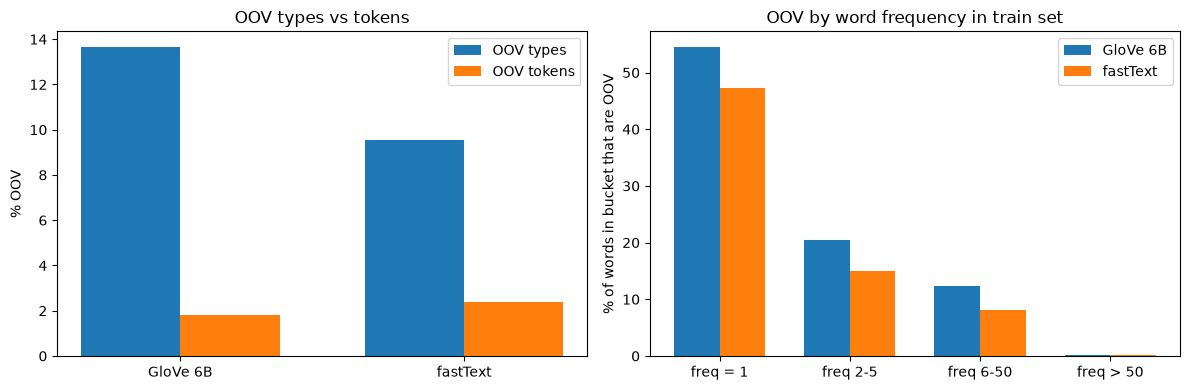

In [5]:
# Anlyse the stats
results = {"GloVe 6B": st_glove, "fastText": st_ft}
df = pd.DataFrame({m: {k: v for k, v in s.items() if k != "top_oov"} for m, s in results.items()}).T
df.insert(0, "Vocab size", len(vocab) - 2)

# Create a table for analysis
display(df.style.format({c: "{:.2%}" for c in df.columns if c != "Vocab size"})
          .set_caption("OOV rate per embedding (lower is better)")
          .highlight_min(axis=0, subset=[c for c in df.columns if c != "Vocab size"], color="#c6efce"))

out_dir = Path("images"); out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / "oov_table.csv")

# Most frequent OOV words
for m, s in results.items():
    print(f"{m} most frequent OOV: {s['top_oov']}")

# Plot the figures to see stats
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
models = list(results)
x = np.arange(len(models)); w = 0.35

axes[0].bar(x - w/2, [results[m]["OOV types"] * 100 for m in models], w, label="OOV types")
axes[0].bar(x + w/2, [results[m]["OOV tokens"] * 100 for m in models], w, label="OOV tokens")
axes[0].set_xticks(x); axes[0].set_xticklabels(models)
axes[0].set_ylabel("% OOV"); axes[0].set_title("OOV types vs tokens"); axes[0].legend()

BUCKETS = {"freq = 1": (1, 1), "freq 2-5": (2, 5), "freq 6-50": (6, 50), "freq > 50": (51, 10**9)}
bnames = list(BUCKETS)
xb = np.arange(len(bnames))
for i, m in enumerate(models):
    axes[1].bar(xb + (i - 0.5) * w, [results[m][b] * 100 for b in bnames], w, label=m)
axes[1].set_xticks(xb); axes[1].set_xticklabels(bnames)
axes[1].set_ylabel("% of words in bucket that are OOV")
axes[1].set_title("OOV by word frequency in train set"); axes[1].legend()
plt.tight_layout()
fig.savefig(out_dir / "oov_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

According to these results, for both methods, there is around 2% of tokens in our training corpus without an embedding mapping. These OOV tokens represent 13.66% and 9.55% of the unique words in the vocabulary using GloVe and fastText, respectively. However, GloVe has a slightly lower OOV token rate (1.81% compared to 2.36% for fastText), meaning that it covers more word occurrences, while fastText covers more unique words. Therefore, from now on we will keep both embeddings for the analysis of our models, as vocabulary coverage alone does not necessarily indicate better classification performance.

It is relevant to mention that fastText can approximate OOV embeddings using character N-grams, but this functionality is not used here, as we are working with pretrained word vectors rather than the complete fastText model. Even with these percentages of unknown vocabulary, most OOV words are relatively infrequent in the PAWS corpus, so their impact on the classification task might be limited. However, this cannot be confirmed from vocabulary coverage alone, and the impact of these missing embeddings will need to be evaluated through the classification experiments. 

However, this is, then, the main limitation of our embedding models. 

Analysing now how good is the embedding to express similarities regarding the task of separating the classes in our model:

In [ ]:
embs = {"GloVe": (glove, E_glove.numpy()), "fastText": (fasttext, E_ft.numpy())}

# Analysis of synonyms scoring higher than antonyms / unrelated words?
pairs = {
    "synonyms":  [("film", "movie"), ("big", "large"), ("begin", "start"), ("city", "town"), ("buy", "purchase")],
    "antonyms":  [("big", "small"), ("buy", "sell"), ("begin", "end"), ("north", "south"), ("win", "lose")],
    "unrelated": [("film", "river"), ("big", "table"), ("buy", "north"), ("city", "blue"), ("start", "fish")],
}
rows = []
for kind, ps in pairs.items():
    row = {"pair type": kind}
    for name, (emb, _) in embs.items():
        sims = [cos_similarity(emb.embed_word(a), emb.embed_word(b)) for a, b in ps if a in emb and b in emb]
        row[name] = np.mean(sims)
    rows.append(row)
display(pd.DataFrame(rows).set_index("pair type").style.format("{:.3f}"))

,GloVe,fastText
pair type,,
synonyms,0.729,0.826
antonyms,0.657,0.790
unrelated,0.185,0.306


We can see in this table that, at word level, both embeddings capture synonyms scoring far above unrelated words (0.73 vs 0.19 for GloVe, 0.83 vs 0.31 for fastText), and paraphrases mostly swapping words for close alternatives. The weakness here is that antonyms sit almost as close as synonyms (0.66 and 0.79), so the space encodes "appears in similar contexts" more than "means the same thing". GloVe separates synonyms from antonyms slightly better (a gap of 0.07 against 0.04), while fastText gives higher similarities across the board, even for unrelated words, so its space looks more compressed. 

However, PAWS rarely depends on antonym substitutions, so this limitation should not matter much, and with only five pairs per category we read this as an illustration rather than proof.

Non-paraphrases with identical bag of words: 8.5%
GloVe: mean cos paraphrase=0.993 | non-paraphrase=0.992 | AUC=0.502
fastText: mean cos paraphrase=0.988 | non-paraphrase=0.988 | AUC=0.493


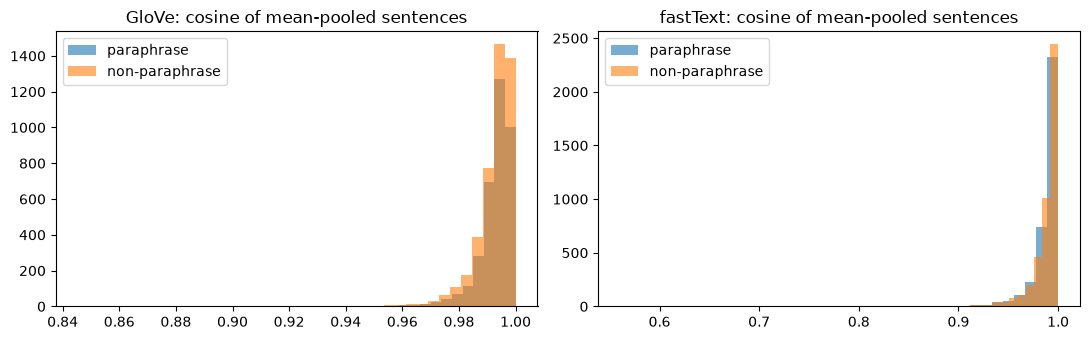

In [ ]:
# Analysing now the mean cosine similarity for both classes and the AUC
def sent_vec(text, E):
    ids = [i for i in tokenizer.ids(text) if i > 1]        # drop <pad>/<unk>
    return E[ids].mean(0) if ids else np.zeros(E.shape[1])

s1, s2 = validation_ds["sentence1"], validation_ds["sentence2"]
labels = np.array(validation_ds["label"])
same_bow = np.array([sorted(tokenizer.tokens(a)) == sorted(tokenizer.tokens(b)) for a, b in zip(s1, s2)])
print(f"Non-paraphrases with identical bag of words: {same_bow[labels == 0].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, (_, E)) in zip(axes, embs.items()):
    sims = np.array([cos_similarity(sent_vec(a, E), sent_vec(b, E)) for a, b in zip(s1, s2)])
    print(f"{name}: mean cos paraphrase={sims[labels == 1].mean():.3f} | "
          f"non-paraphrase={sims[labels == 0].mean():.3f} | AUC={roc_auc_score(labels, sims):.3f}")
    ax.hist(sims[labels == 1], bins=40, alpha=.6, label="paraphrase")
    ax.hist(sims[labels == 0], bins=40, alpha=.6, label="non-paraphrase")
    ax.set_title(f"{name}: cosine of mean-pooled sentences"); ax.legend()
plt.tight_layout()
fig.savefig(out_dir / "cos_mean-pooled_sentences_both_embbeds.png", dpi=300, bbox_inches="tight")
plt.show()

At sentence level the picture of "which embedding makes both classes more distinguishable" is rather weak. Mean-pooled vectors are almost identical for paraphrases and non-paraphrases (mean cosine 0.993 vs 0.992 for GloVe and 0.988 vs 0.988 for fastText), the histograms overlap almost completely; and the AUC is around 0.5 for both embeddings, which is chance level. 

This is expected from how PAWS is built, as both sentences in a pair reuse nearly the same words, and 8.5% of the non-paraphrases are pure reorderings with an identical bag of words, which any order-agnostic model sees as the same input. So, the embeddings represent word similarity well, but that alone cannot separate PAWS pairs; the signal has to come from word order, which motivates comparing Embed and Pool against a GRU.